In [1]:
import os, glob, math, time, random
import numpy as np
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models
import torchvision.transforms as T
from torchvision.ops import nms

import matplotlib.pyplot as plt
import matplotlib.patches as patches

# ------- Cau hinh chung -------
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DATA_ROOT = "D:/DuyToan/Python/DUT_AI/day 46 7-7-2026/data/GARBAGE CLASSIFICATION"
CLASS_NAMES = ['BIODEGRADABLE', 'CARDBOARD', 'GLASS', 'METAL', 'PAPER', 'PLASTIC']
NUM_CLASSES = len(CLASS_NAMES)          # 6 lop
NUM_CLASSES_BG = NUM_CLASSES + 1        # +1 cho background (nhan 0)

IMG_SIZE = 416          # anh da resize san 416x416
FEAT_STRIDE = 32        # ResNet18 (bo 2 lop cuoi) giam 32 lan -> feature 13x13
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("Device:", DEVICE)

Device: cuda


In [2]:
class GarbageDataset(torch.utils.data.Dataset):
    """Doc anh + nhan YOLO -> tra ve (anh_tensor, boxes_xyxy, labels)."""
    def __init__(self, root, split):
        self.img_dir = os.path.join(root, split, "images")
        self.lbl_dir = os.path.join(root, split, "labels")
        self.img_paths = sorted(glob.glob(os.path.join(self.img_dir, "*.jpg")))
        self.to_tensor = T.Compose([
            T.Resize((IMG_SIZE, IMG_SIZE)),
            T.ToTensor(),
            T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

    def __len__(self):
        return len(self.img_paths)

    def _load_label(self, img_path):
        name = os.path.splitext(os.path.basename(img_path))[0]
        lbl_path = os.path.join(self.lbl_dir, name + ".txt")
        boxes, labels = [], []
        if os.path.exists(lbl_path):
            with open(lbl_path) as f:
                for line in f:
                    p = line.split()
                    if len(p) != 5:
                        continue
                    c, cx, cy, w, h = int(p[0]), float(p[1]), float(p[2]), float(p[3]), float(p[4])
                    x1 = (cx - w/2) * IMG_SIZE; y1 = (cy - h/2) * IMG_SIZE
                    x2 = (cx + w/2) * IMG_SIZE; y2 = (cy + h/2) * IMG_SIZE
                    boxes.append([x1, y1, x2, y2])
                    labels.append(c + 1)          # +1: nhan 0 danh cho background
        boxes = torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4)
        labels = torch.tensor(labels, dtype=torch.int64)
        return boxes, labels

    def __getitem__(self, idx):
        img_path = self.img_paths[idx]
        img = Image.open(img_path).convert("RGB")
        img_t = self.to_tensor(img)
        boxes, labels = self._load_label(img_path)
        return img_t, boxes, labels

So anh: 7324 2098 1042


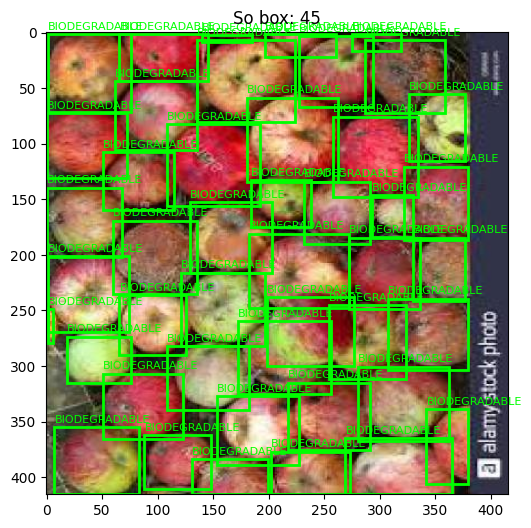

In [3]:
train_ds = GarbageDataset(DATA_ROOT, "train")
valid_ds = GarbageDataset(DATA_ROOT, "valid")
test_ds  = GarbageDataset(DATA_ROOT, "test")
print("So anh:", len(train_ds), len(valid_ds), len(test_ds))

img_t, boxes, labels = train_ds[0]
mean = torch.tensor([0.485,0.456,0.406]).view(3,1,1)
std  = torch.tensor([0.229,0.224,0.225]).view(3,1,1)
img_show = (img_t*std + mean).permute(1,2,0).clamp(0,1).numpy()   # bo chuan hoa de xem

fig, ax = plt.subplots(figsize=(6,6))
ax.imshow(img_show)
for b, l in zip(boxes, labels):
    x1,y1,x2,y2 = b.tolist()
    ax.add_patch(patches.Rectangle((x1,y1), x2-x1, y2-y1, fill=False, color='lime', linewidth=2))
    ax.text(x1, y1-4, CLASS_NAMES[l.item()-1], color='lime', fontsize=8)
ax.set_title(f"So box: {len(boxes)}"); plt.show()

In [4]:
def box_iou(a, b):
    """IoU giua 2 tap box xyxy. a:(N,4) b:(M,4)"""
    area_a = (a[:,2]-a[:,0]).clamp(min=0)*(a[:,3]-a[:,1]).clamp(min=0)
    area_b = (b[:,2]-b[:,0]).clamp(min=0)*(b[:,3]-b[:,1]).clamp(min=0)
    lt = torch.max(a[:,None,:2], b[None,:,:2])
    rb = torch.min(a[:,None,2:], b[None,:,2:])
    wh = (rb-lt).clamp(min=0)
    inter = wh[:,:,0]*wh[:,:,1]
    union = area_a[:,None] + area_b[None,:] - inter
    return inter / union.clamp(min=1e-6)

def generate_anchors(scales, ratios):
    """Anchor goc (A,4) xyxy, tam tai (0,0)."""
    anchors = []
    for s in scales:
        for r in ratios:
            w = s*math.sqrt(r); h = s/math.sqrt(r)
            anchors.append([-w/2, -h/2, w/2, h/2])
    return torch.tensor(anchors, dtype=torch.float32)

def shift_anchors(base_anchors, feat_h, feat_w, stride):
    """Rai anchor goc ra khap luoi feature -> (H*W*A, 4)."""
    dev = base_anchors.device
    shift_x = (torch.arange(feat_w, device=dev)+0.5)*stride
    shift_y = (torch.arange(feat_h, device=dev)+0.5)*stride
    yy, xx = torch.meshgrid(shift_y, shift_x, indexing='ij')
    shifts = torch.stack([xx.reshape(-1), yy.reshape(-1),
                          xx.reshape(-1), yy.reshape(-1)], dim=1)   # (H*W,4)
    anchors = shifts[:,None,:] + base_anchors[None,:,:]             # (H*W,A,4)
    return anchors.reshape(-1, 4)

def encode_boxes(gt, anchors):
    """box -> delta (dx,dy,dw,dh) de lam nhan hoc."""
    aw=anchors[:,2]-anchors[:,0]; ah=anchors[:,3]-anchors[:,1]
    ax=anchors[:,0]+0.5*aw;       ay=anchors[:,1]+0.5*ah
    gw=gt[:,2]-gt[:,0];           gh=gt[:,3]-gt[:,1]
    gx=gt[:,0]+0.5*gw;            gy=gt[:,1]+0.5*gh
    return torch.stack([(gx-ax)/aw, (gy-ay)/ah, torch.log(gw/aw), torch.log(gh/ah)], dim=1)

def decode_boxes(deltas, anchors):
    """delta -> box xyxy du doan."""
    aw=anchors[:,2]-anchors[:,0]; ah=anchors[:,3]-anchors[:,1]
    ax=anchors[:,0]+0.5*aw;       ay=anchors[:,1]+0.5*ah
    dx,dy,dw,dh = deltas[:,0],deltas[:,1],deltas[:,2],deltas[:,3]
    dw = torch.clamp(dw, max=10.0); dh = torch.clamp(dh, max=10.0) # Van an toan 1: chong tran exp
    px=dx*aw+ax; py=dy*ah+ay; pw=torch.exp(dw)*aw; ph=torch.exp(dh)*ah
    return torch.stack([px-0.5*pw, py-0.5*ph, px+0.5*pw, py+0.5*ph], dim=1)

In [5]:
class RPN(nn.Module):
    """Region Proposal Network tu code: sinh anchor, cham objectness + tinh tinh box."""
    def __init__(self, in_channels=512, mid=256, scales=(64,128,256), ratios=(0.5,1.0,2.0)):
        super().__init__()
        self.base_anchors = generate_anchors(list(scales), list(ratios))   # (A,4)
        self.num_anchors = self.base_anchors.size(0) # A=9
        self.conv = nn.Conv2d(in_channels, mid, 3, padding=1)
        self.cls_logits = nn.Conv2d(mid, self.num_anchors, 1)              # 1 diem/anchor
        self.bbox_pred  = nn.Conv2d(mid, self.num_anchors * 4, 1)          # 4 delta/anchor
        self.pre_nms_topn=2000; self.post_nms_topn=300; self.nms_thresh=0.7
        self.pos_iou=0.7; self.neg_iou=0.3; self.num_samples=256; self.pos_ratio=0.5

    def forward(self, feature_map, gt_boxes, img_size):
        N,C,H,W = feature_map.shape
        device = feature_map.device
        t = F.relu(self.conv(feature_map))
        cls = self.cls_logits(t).permute(0,2,3,1).reshape(-1)          # (H*W*A,)
        reg = self.bbox_pred(t).permute(0,2,3,1).reshape(-1,4)          # (H*W*A,4)
        anchors = shift_anchors(self.base_anchors.to(device), H, W, FEAT_STRIDE).to(device)

        # ----- Sinh proposal -----
        scores = torch.sigmoid(cls.detach())
        proposals = decode_boxes(reg.detach(), anchors)
        proposals[:,0::2] = proposals[:,0::2].clamp(0, img_size)
        proposals[:,1::2] = proposals[:,1::2].clamp(0, img_size)
        ws = proposals[:,2]-proposals[:,0]; hs = proposals[:,3]-proposals[:,1]
        keep = (ws>=1)&(hs>=1)
        proposals, scores = proposals[keep], scores[keep]
        n_pre = min(self.pre_nms_topn, scores.size(0))
        top = scores.topk(n_pre).indices
        proposals, scores = proposals[top], scores[top]
        keep = nms(proposals, scores, self.nms_thresh)[:self.post_nms_topn]
        proposals = proposals[keep]

        # ----- Loss RPN (chi khi co gt) -----
        loss_cls = torch.tensor(0.0, device=device)
        loss_reg = torch.tensor(0.0, device=device)
        if gt_boxes is not None and gt_boxes.numel() > 0:
            ious = box_iou(anchors, gt_boxes)
            max_iou, gt_assign = ious.max(dim=1)
            labels = torch.full((anchors.size(0),), -1.0, device=device)   # -1: bo qua
            labels[max_iou < self.neg_iou] = 0
            labels[max_iou >= self.pos_iou] = 1
            labels[ious.argmax(dim=0)] = 1        # moi gt co it nhat 1 anchor duong
            pos_idx = torch.where(labels==1)[0]; neg_idx = torch.where(labels==0)[0]
            n_pos = min(int(self.num_samples*self.pos_ratio), pos_idx.numel())
            n_neg = min(self.num_samples-n_pos, neg_idx.numel())
            pos_idx = pos_idx[torch.randperm(pos_idx.numel(), device=device)[:n_pos]]
            neg_idx = neg_idx[torch.randperm(neg_idx.numel(), device=device)[:n_neg]]
            samp = torch.cat([pos_idx, neg_idx])
            loss_cls = F.binary_cross_entropy_with_logits(cls[samp], labels[samp])
            if n_pos > 0:
                tgt = encode_boxes(gt_boxes[gt_assign[pos_idx]], anchors[pos_idx])
                loss_reg = F.smooth_l1_loss(reg[pos_idx], tgt)
        return proposals, loss_cls, loss_reg

In [6]:
from torchvision.ops import roi_pool

class RoIPooling(nn.Module):
    """RoI Pooling chay THANG tren GPU (torchvision.ops.roi_pool).
    Thay ban tu code co vong for + .item() (moi .item() ep GPU dong bo voi CPU
    -> nghen). Ban nay vectorized hoan toan -> GPU chay ~100%."""
    def __init__(self, output_size, spatial_scale):
        super().__init__()
        if isinstance(output_size, int):
            self.output_size = (output_size, output_size)
        else:
            self.output_size = output_size
        self.spatial_scale = spatial_scale

    def forward(self, feature_map, rois):
        # rois: (N,4) xyxy o toa do anh goc. roi_pool tu nhan spatial_scale.
        # Truyen dang list [rois] -> torchvision hieu tat ca thuoc anh 0 (batch=1).
        return roi_pool(feature_map, [rois], self.output_size, self.spatial_scale)


In [7]:
class FasterRCNN(nn.Module):
    """Faster R-CNN = Backbone + RPN(tu code) + Head."""
    def __init__(self, num_classes_bg):
        super().__init__()
        self.num_classes_bg = num_classes_bg
        resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        self.backbone = nn.Sequential(*list(resnet.children())[:-2])   # -> (1,512,13,13)
        for layer in list(self.backbone.children())[:-2]:
            for p in layer.parameters(): p.requires_grad = False
        self.spatial_scale = 1.0/FEAT_STRIDE
        self.rpn = RPN(in_channels=512)
        self.roi_pool = RoIPooling(output_size=7, spatial_scale=self.spatial_scale)
        self.fc = nn.Sequential(
            nn.Linear(512*7*7, 1024), nn.ReLU(),
            nn.Linear(1024, 1024), nn.ReLU(), nn.Dropout(0.5))
        self.cls_head  = nn.Linear(1024, num_classes_bg)
        self.bbox_head = nn.Linear(1024, num_classes_bg * 4)
        self.pos_iou=0.5; self.roi_batch=128; self.pos_ratio=0.25

    def sample_rois(self, proposals, gt_boxes, gt_labels):
        ious = box_iou(proposals, gt_boxes)
        max_iou, assign = ious.max(dim=1)
        labels = gt_labels[assign]
        labels[max_iou < self.pos_iou] = 0
        pos_idx = torch.where(max_iou >= self.pos_iou)[0]
        neg_idx = torch.where(max_iou < self.pos_iou)[0]
        n_pos = min(int(self.roi_batch*self.pos_ratio), pos_idx.numel())
        n_neg = min(self.roi_batch-n_pos, neg_idx.numel())
        d = proposals.device
        pos_idx = pos_idx[torch.randperm(pos_idx.numel(), device=d)[:n_pos]]
        neg_idx = neg_idx[torch.randperm(neg_idx.numel(), device=d)[:n_neg]]
        keep = torch.cat([pos_idx, neg_idx])
        return proposals[keep], labels[keep], assign[keep]

    def forward(self, image, gt_boxes=None, gt_labels=None):
        feat = self.backbone(image)
        return self._detect_head(feat, gt_boxes, gt_labels)

    def _detect_head(self, feat, gt_boxes=None, gt_labels=None):
        # Tach rieng phan sau backbone -> cho phep chay backbone theo BATCH
        # (nhieu anh 1 luot) roi goi ham nay cho tung feature map -> GPU no viec hon.
        proposals, loss_rpn_cls, loss_rpn_reg = self.rpn(feat, gt_boxes, IMG_SIZE)
        training = self.training and gt_boxes is not None and gt_boxes.numel() > 0
        if training:
            rois, roi_labels, assign = self.sample_rois(proposals, gt_boxes, gt_labels)
        else:
            rois = proposals
        x = self.fc(self.roi_pool(feat, rois).flatten(1))
        cls_scores = self.cls_head(x)
        bbox_preds = self.bbox_head(x)                      # (N,28)
        if training:
            loss_cls = F.cross_entropy(cls_scores, roi_labels)
            loss_box = torch.tensor(0.0, device=feat.device)
            pos = torch.where(roi_labels > 0)[0]
            if pos.numel() > 0:
                tgt = encode_boxes(gt_boxes[assign[pos]], rois[pos])
                pred = bbox_preds.view(-1, self.num_classes_bg, 4)[pos, roi_labels[pos]]
                loss_box = F.smooth_l1_loss(pred, tgt)
            with torch.no_grad():   # accuracy phan loai RoI (de theo doi khi train)
                roi_acc = (cls_scores.argmax(1) == roi_labels).float().mean()
            return {'rpn_cls':loss_rpn_cls, 'rpn_reg':loss_rpn_reg,
                    'roi_cls':loss_cls, 'roi_box':loss_box, 'acc':roi_acc}
        return self.postprocess(cls_scores, bbox_preds, rois)

    @torch.no_grad()
    def postprocess(self, cls_scores, bbox_preds, rois, score_thresh=0.5, nms_thresh=0.3):
        probs = F.softmax(cls_scores, dim=1)
        bbox_preds = bbox_preds.view(-1, self.num_classes_bg, 4)
        ob, os_, ol = [], [], []
        for c in range(1, self.num_classes_bg):
            sc = probs[:, c]; mask = sc > score_thresh
            if mask.sum() == 0: continue
            boxes_c = decode_boxes(bbox_preds[mask, c], rois[mask])
            boxes_c[:,0::2] = boxes_c[:,0::2].clamp(0, IMG_SIZE)
            boxes_c[:,1::2] = boxes_c[:,1::2].clamp(0, IMG_SIZE)
            keep = nms(boxes_c, sc[mask], nms_thresh)
            ob.append(boxes_c[keep]); os_.append(sc[mask][keep])
            ol.append(torch.full((keep.numel(),), c, device=rois.device))
        if ob: return torch.cat(ob), torch.cat(os_), torch.cat(ol)
        return torch.empty(0, 4, device=rois.device), torch.empty(0, device=rois.device), torch.empty(0, dtype=torch.int64, device=rois.device)

In [8]:
# --- Smoke test 1 anh (chay thu truoc khi train dai) ---
model = FasterRCNN(NUM_CLASSES_BG).to(DEVICE)
model.train()
_img,_b,_l = train_ds[0]
_out = model(_img.unsqueeze(0).to(DEVICE), _b.to(DEVICE), _l.to(DEVICE))
print("Smoke test:", {k: round(v.item(),4) for k, v in _out.items()})

def train_model(model, dataset, epochs=20, lr=0.1, backbone_bs=4, log_every=500):
    """Train Faster R-CNN.
    Toi uu GPU: chay BACKBONE theo batch (backbone_bs anh 1 luot) roi xu ly
    detection head cho tung anh -> GPU 'no viec' hon, util cao hon batch=1.
    """
    model.to(DEVICE); model.train()
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=5e-4)
    n = len(dataset)
    for ep in range(epochs):
        order = torch.randperm(n).tolist()
        ep_loss=0.0; ep_acc=0.0; seen=0; t0=time.time()
        # duyet theo tung NHOM backbone_bs anh
        for start in range(0, n, backbone_bs):
            batch_idx = order[start:start+backbone_bs]
            imgs, gts, lbs = [], [], []
            for j in batch_idx:
                im, bb, ll = dataset[j]
                if bb.numel()==0: continue
                imgs.append(im); gts.append(bb.to(DEVICE)); lbs.append(ll.to(DEVICE))
            if not imgs: continue
            # chay BACKBONE 1 luot cho ca nhom
            img_batch = torch.stack(imgs).to(DEVICE)          # (B,3,416,416)
            feats = model.backbone(img_batch)                 # (B,512,13,13)
            # gom loss cua ca nhom roi backward 1 lan
            batch_loss = 0.0
            for bi in range(feats.size(0)):
                out = model._detect_head(feats[bi:bi+1], gts[bi], lbs[bi])
                loss = out['rpn_cls']+out['rpn_reg']+out['roi_cls']+out['roi_box']
                if torch.isfinite(loss):     # bo qua buoc loss inf/nan (chong no)
                    batch_loss = batch_loss + loss
                    ep_acc += out['acc'].item(); seen += 1
            if isinstance(batch_loss, float): continue
            opt.zero_grad()
            batch_loss.backward()
            torch.nn.utils.clip_grad_norm_(params, 10.0)      # chong no gradient
            opt.step()
            ep_loss += batch_loss.item()
            if seen>0 and (start//backbone_bs) % (log_every//backbone_bs) == 0 and start>0:
                print(f"  Epoch {ep+1} | {start}/{n} | loss {ep_loss/seen:.4f} | acc {ep_acc/seen:.3f} | {time.time()-t0:.0f}s")
        avg_loss=ep_loss/max(seen,1); avg_acc=ep_acc/max(seen,1)
        print(f"== Epoch {ep+1}/{epochs} DONE | loss {avg_loss:.4f} | acc {avg_acc:.3f} | {time.time()-t0:.0f}s ==")
        torch.save(model.state_dict(), "faster_rcnn_garbage.pth")
    return model

model = train_model(model, train_ds, epochs=10, lr=1e-3, backbone_bs=4)


Smoke test: {'rpn_cls': 0.71, 'rpn_reg': 0.0698, 'roi_cls': 2.0433, 'roi_box': 0.0524, 'acc': 0.0625}
  Epoch 1 | 500/7324 | loss 0.7798 | acc 0.924 | 20s
  Epoch 1 | 1000/7324 | loss 0.6694 | acc 0.918 | 38s
  Epoch 1 | 1500/7324 | loss 0.6170 | acc 0.912 | 61s
  Epoch 1 | 2000/7324 | loss 0.5901 | acc 0.907 | 84s
  Epoch 1 | 2500/7324 | loss 0.5700 | acc 0.904 | 107s
  Epoch 1 | 3000/7324 | loss 0.5527 | acc 0.903 | 131s
  Epoch 1 | 3500/7324 | loss 0.5428 | acc 0.902 | 155s
  Epoch 1 | 4000/7324 | loss 0.5323 | acc 0.901 | 180s
  Epoch 1 | 4500/7324 | loss 0.5212 | acc 0.901 | 206s
  Epoch 1 | 5000/7324 | loss 0.5155 | acc 0.901 | 231s
  Epoch 1 | 5500/7324 | loss 0.5090 | acc 0.900 | 257s
  Epoch 1 | 6000/7324 | loss 0.5018 | acc 0.900 | 283s
  Epoch 1 | 6500/7324 | loss 0.4959 | acc 0.899 | 306s
  Epoch 1 | 7000/7324 | loss 0.4909 | acc 0.899 | 329s
== Epoch 1/10 DONE | loss 0.4877 | acc 0.898 | 342s ==
  Epoch 2 | 500/7324 | loss 0.3994 | acc 0.893 | 11s
  Epoch 2 | 1000/7324 | l

In [9]:
@torch.no_grad()
def evaluate_map(model, dataset, iou_thresh=0.5, max_images=300):
    """Tu code mAP@0.5: gom TP/FP moi lop -> AP trung binh."""
    model.eval().to(DEVICE)
    aps = []
    for c in range(1, NUM_CLASSES_BG):
        scores_all, tp_all, n_gt = [], [], 0
        for i in range(min(max_images, len(dataset))):
            img, gtb, gtl = dataset[i]
            gt_c = gtb[gtl == c]
            n_gt += gt_c.size(0)
            boxes, scores, labels = model(img.unsqueeze(0).to(DEVICE))
            boxes, scores, labels = boxes.cpu(), scores.cpu(), labels.cpu()
            m = (labels == c)
            pb, ps = boxes[m], scores[m]
            if pb.size(0) > 0:
                order = ps.argsort(descending=True)
                pb, ps = pb[order], ps[order]
                matched = torch.zeros(gt_c.size(0))
                for k in range(pb.size(0)):
                    tp = 0
                    if gt_c.size(0) > 0:
                        iou = box_iou(pb[k:k+1], gt_c)[0]
                        j = iou.argmax().item()
                        if iou[j] >= iou_thresh and matched[j] == 0:
                            tp = 1; matched[j] = 1
                    scores_all.append(ps[k].item())
                    tp_all.append(tp)
        if n_gt == 0:
            continue
        if len(scores_all) == 0:
            aps.append(0.0); continue
        idx = np.argsort(-np.array(scores_all))
        tp = np.array(tp_all)[idx]; fp = 1 - tp
        tp_c, fp_c = np.cumsum(tp), np.cumsum(fp)
        recall = tp_c / (n_gt + 1e-6)
        precision = tp_c / (tp_c + fp_c + 1e-6)
        ap = 0.0                              # 11-point interpolation
        for t in np.linspace(0, 1, 11):
            p = precision[recall >= t].max() if (recall >= t).any() else 0
            ap += p / 11
        aps.append(ap)
        print(f"  {CLASS_NAMES[c-1]:14s} AP@0.5 = {ap:.3f}")
    mAP = float(np.mean(aps)) if aps else 0.0
    print(f"mAP@0.5 = {mAP:.3f}")
    return mAP

mAP = evaluate_map(model, test_ds, max_images=300)

  BIODEGRADABLE  AP@0.5 = 0.091
  CARDBOARD      AP@0.5 = 0.020
  METAL          AP@0.5 = 0.534
  PAPER          AP@0.5 = 0.266
  PLASTIC        AP@0.5 = 0.007
mAP@0.5 = 0.184


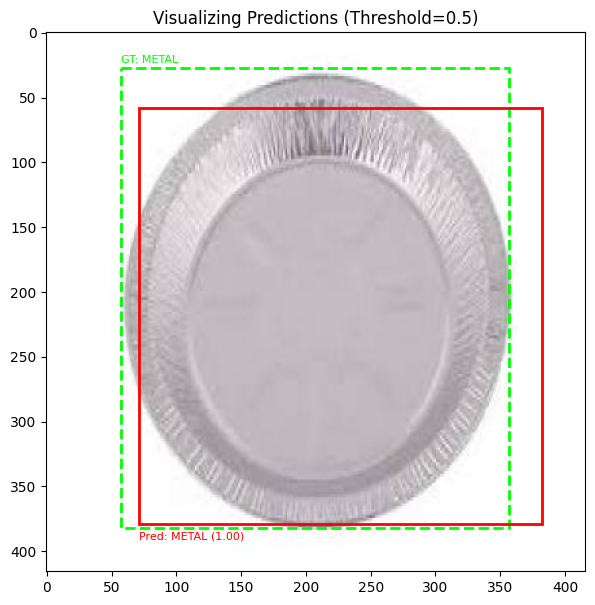

In [10]:
@torch.no_grad()
def plot_prediction(model, dataset, idx, threshold=0.5):
    model.eval().to(DEVICE)
    img, gtb, gtl = dataset[idx]
    boxes, scores, labels = model(img.unsqueeze(0).to(DEVICE))
    boxes, scores, labels = boxes.cpu(), scores.cpu(), labels.cpu()
    
    keep = scores >= threshold
    boxes, scores, labels = boxes[keep], scores[keep], labels[keep]
    
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)
    img_show = (img*std + mean).permute(1,2,0).clamp(0,1).numpy()
    
    fig, ax = plt.subplots(figsize=(7,7))
    ax.imshow(img_show)
    
    for b, l in zip(gtb, gtl):
        x1, y1, x2, y2 = b.tolist()
        ax.add_patch(patches.Rectangle((x1,y1), x2-x1, y2-y1, fill=False, color='lime', linewidth=2, linestyle='--'))
        ax.text(x1, y1-4, f"GT: {CLASS_NAMES[l.item()-1]}", color='lime', fontsize=8)
        
    for b, s, l in zip(boxes, scores, labels):
        x1, y1, x2, y2 = b.tolist()
        ax.add_patch(patches.Rectangle((x1,y1), x2-x1, y2-y1, fill=False, color='red', linewidth=2))
        ax.text(x1, y2+12, f"Pred: {CLASS_NAMES[l.item()-1]} ({s.item():.2f})", color='red', fontsize=8)
        
    ax.set_title(f"Visualizing Predictions (Threshold={threshold})")
    plt.show()

plot_prediction(model, test_ds, idx=15, threshold=0.5)

In [11]:
# Bang so sanh 3 mo hinh (in ra thay cho cell markdown)
compare = [
    ['Tieu chi',            'R-CNN',              'Fast R-CNN',        'Faster R-CNN'],
    ['Proposal',            'Selective Search',   'Selective Search',  'RPN (tu code)'],
    ['Chay CNN',            '~2000 lan/anh',      '1 lan/anh',         '1 lan/anh (chia se)'],
    ['Gom dac trung',       'Resize crop tho',    'RoI Pooling',       'RoI Pooling'],
    ['Training',            'Nhieu giai doan',    '1 giai doan',       'End-to-End'],
    ['Toc do (tuong doi)',  'Rat cham',           'Nhanh hon nhieu',   'Nhanh nhat'],
]
w = [max(len(r[i]) for r in compare) for i in range(4)]
for r in compare:
    print(' | '.join(r[i].ljust(w[i]) for i in range(4)))
print()
print("Nhan xet: Faster R-CNN thay Selective Search bang RPN chay tren GPU va chia se")
print("feature map voi detection head -> train end-to-end, nhanh va gon hon 2 doi truoc.")


Tieu chi           | R-CNN            | Fast R-CNN       | Faster R-CNN       
Proposal           | Selective Search | Selective Search | RPN (tu code)      
Chay CNN           | ~2000 lan/anh    | 1 lan/anh        | 1 lan/anh (chia se)
Gom dac trung      | Resize crop tho  | RoI Pooling      | RoI Pooling        
Training           | Nhieu giai doan  | 1 giai doan      | End-to-End         
Toc do (tuong doi) | Rat cham         | Nhanh hon nhieu  | Nhanh nhat         

Nhan xet: Faster R-CNN thay Selective Search bang RPN chay tren GPU va chia se
feature map voi detection head -> train end-to-end, nhanh va gon hon 2 doi truoc.
